# Assignment 5
## Name: Ankur De
## Roll number: BL.SC.U4AIE24105

In [3]:
"""
Lab: Multi-window Gaussian distributions for grey values of each class.

Steps:
  1. Load the label volume (LabelsForTraining.nii) and the intensity volume(s)
     (T1.nii, T2_FLAIR.nii) as 3D matrices.
  2. Group voxels by class label (0..8 here, 0 = background).
  3. For each class, plot a histogram of its grey values and fit a
     Gaussian (mean, std) on top of it.
  4. Overlay all class Gaussians in one "multi-window" plot.

Usage:
    python gaussian_class_fit.py

Requires: nibabel, numpy, matplotlib, scipy
    pip install nibabel numpy matplotlib scipy
"""

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from scipy.stats import norm

# ------------------------------------------------------------------
# 1. File paths -- edit these if your files are named differently
# ------------------------------------------------------------------
LABELS_PATH = "/run/media/ankur-de/Data/Ankur/Study/Semester 5/Probablistic Reasoning/Lab/Probablistic Reasoning/src/main/java/com/ankur/Lab_5/data/LabelsForTraining.nii"
T1_PATH = "/run/media/ankur-de/Data/Ankur/Study/Semester 5/Probablistic Reasoning/Lab/Probablistic Reasoning/src/main/java/com/ankur/Lab_5/data/T1.nii"
T2_FLAIR_PATH = "/run/media/ankur-de/Data/Ankur/Study/Semester 5/Probablistic Reasoning/Lab/Probablistic Reasoning/src/main/java/com/ankur/Lab_5/data/T2_FLAIR.nii"

# Which intensity volume to build the class distributions from.
# Change to T2_FLAIR_PATH if you want to do the FLAIR image instead,
# or run the script twice (once per modality) since the lab asks you
# to characterize grey values per class.
INTENSITY_PATH = T1_PATH

In [4]:
def load_nii_as_matrix(path):
    """Load a .nii file and return it as a 3D numpy array."""
    img = nib.load(path)
    data = img.get_fdata()
    return data

In [5]:
def group_voxels_by_class(labels, intensities):
    """
    Given a label volume and an intensity volume of the same shape,
    return a dict: {class_id: 1D numpy array of grey values for that class}
    """
    assert labels.shape == intensities.shape, (
        f"Shape mismatch: labels {labels.shape} vs intensities {intensities.shape}"
    )

    class_ids = np.unique(labels).astype(int)
    class_voxels = {}
    for c in class_ids:
        mask = labels == c
        class_voxels[c] = intensities[mask]
    return class_voxels

In [6]:
def fit_gaussian(values):
    """Fit a Gaussian (mean, std) to a 1D array of values using MLE."""
    mu, sigma = norm.fit(values)
    return mu, sigma

In [7]:

def plot_class_histograms_with_gaussians(class_voxels, exclude_background=True,
                                          bins=100, save_path=None):
    """
    For each class, plot a histogram of grey values with the fitted
    Gaussian curve overlaid. All classes are drawn on the same axes
    ("multi-window" view) so you can see how much they overlap.
    """
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = plt.cm.tab10.colors

    fit_results = {}

    for i, (cls, values) in enumerate(sorted(class_voxels.items())):
        if exclude_background and cls == 0:
            continue
        if values.size == 0:
            continue

        color = colors[i % len(colors)]

        # Normalized histogram (density=True) so it's on the same
        # vertical scale as the Gaussian pdf
        ax.hist(values, bins=bins, density=True, alpha=0.35,
                color=color, label=f"Class {cls} (n={values.size})")

        mu, sigma = fit_gaussian(values)
        fit_results[cls] = (mu, sigma)

        x = np.linspace(values.min(), values.max(), 500)
        pdf = norm.pdf(x, mu, sigma)
        ax.plot(x, pdf, color=color, linewidth=2,
                label=f"Class {cls} fit: μ={mu:.1f}, σ={sigma:.1f}")

    ax.set_xlabel("Grey value (intensity)")
    ax.set_ylabel("Density")
    ax.set_title("Multi-window Gaussian distributions per class")
    ax.legend(fontsize=8, loc="upper right")
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=150)
        print(f"Saved plot to {save_path}")

    plt.show()
    return fit_results

In [8]:
def plot_individual_class_histograms(class_voxels, exclude_background=True,
                                      bins=100, save_path=None):
    """
    Optional: one subplot per class instead of overlaying everything,
    which is often easier to read/report when classes overlap a lot.
    """
    classes = sorted(c for c in class_voxels if not (exclude_background and c == 0)
                      and class_voxels[c].size > 0)
    n = len(classes)
    ncols = 3
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, cls in zip(axes, classes):
        values = class_voxels[cls]
        mu, sigma = fit_gaussian(values)

        ax.hist(values, bins=bins, density=True, alpha=0.5, color="steelblue")
        x = np.linspace(values.min(), values.max(), 500)
        ax.plot(x, norm.pdf(x, mu, sigma), color="red", linewidth=2)
        ax.set_title(f"Class {cls}: μ={mu:.1f}, σ={sigma:.1f}, n={values.size}")
        ax.set_xlabel("Grey value")
        ax.set_ylabel("Density")

    # hide any unused axes
    for ax in axes[len(classes):]:
        ax.axis("off")

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
        print(f"Saved plot to {save_path}")
    plt.show()

In [9]:
def main():
    print("Loading volumes...")
    labels = load_nii_as_matrix(LABELS_PATH)
    intensities = load_nii_as_matrix(INTENSITY_PATH)

    print(f"Label volume shape:     {labels.shape}")
    print(f"Intensity volume shape: {intensities.shape}")

    class_ids, counts = np.unique(labels, return_counts=True)
    print("\nClass voxel counts:")
    for c, n in zip(class_ids.astype(int), counts):
        print(f"  Class {c}: {n} voxels")

    print("\nGrouping voxels by class...")
    class_voxels = group_voxels_by_class(labels, intensities)

    print("\nFitting Gaussians per class...")
    fit_results = plot_class_histograms_with_gaussians(
        class_voxels, exclude_background=True, save_path="class_gaussians_overlay.png"
    )

    print("\nFitted (mu, sigma) per class:")
    for cls, (mu, sigma) in sorted(fit_results.items()):
        print(f"  Class {cls}: mu={mu:.3f}, sigma={sigma:.3f}")

    # Optional: individual subplots, easier to read for a report
    plot_individual_class_histograms(
        class_voxels, exclude_background=True, save_path="class_gaussians_grid.png"
    )

Loading volumes...
Label volume shape:     (240, 240, 48)
Intensity volume shape: (240, 240, 48)

Class voxel counts:
  Class 0: 2261444 voxels
  Class 1: 155930 voxels
  Class 2: 11943 voxels
  Class 3: 123979 voxels
  Class 4: 605 voxels
  Class 5: 150374 voxels
  Class 6: 13701 voxels
  Class 7: 39065 voxels
  Class 8: 7759 voxels

Grouping voxels by class...

Fitting Gaussians per class...
Saved plot to class_gaussians_overlay.png


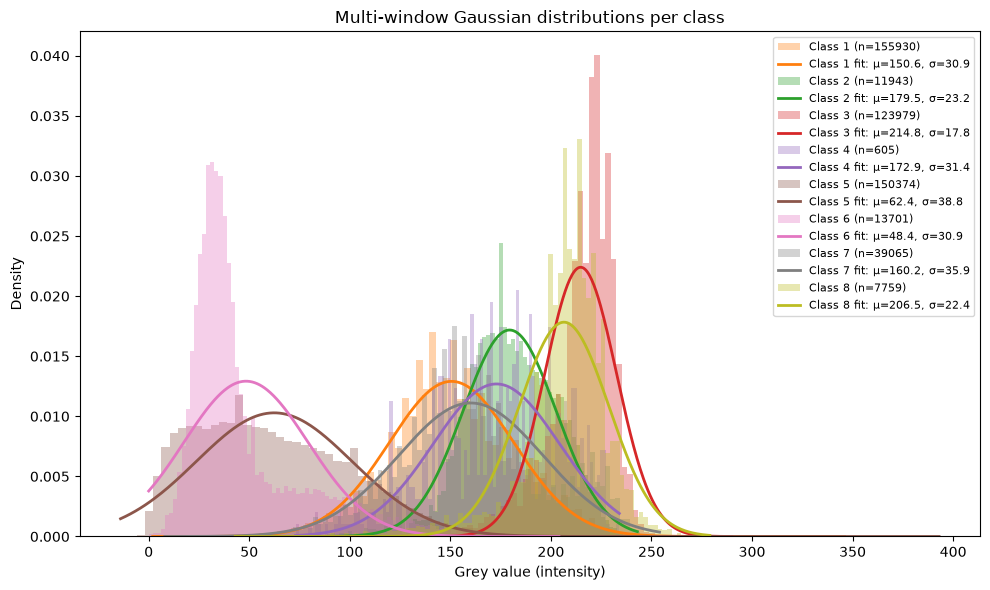


Fitted (mu, sigma) per class:
  Class 1: mu=150.574, sigma=30.906
  Class 2: mu=179.459, sigma=23.222
  Class 3: mu=214.778, sigma=17.809
  Class 4: mu=172.893, sigma=31.431
  Class 5: mu=62.396, sigma=38.776
  Class 6: mu=48.382, sigma=30.873
  Class 7: mu=160.184, sigma=35.914
  Class 8: mu=206.476, sigma=22.372
Saved plot to class_gaussians_grid.png


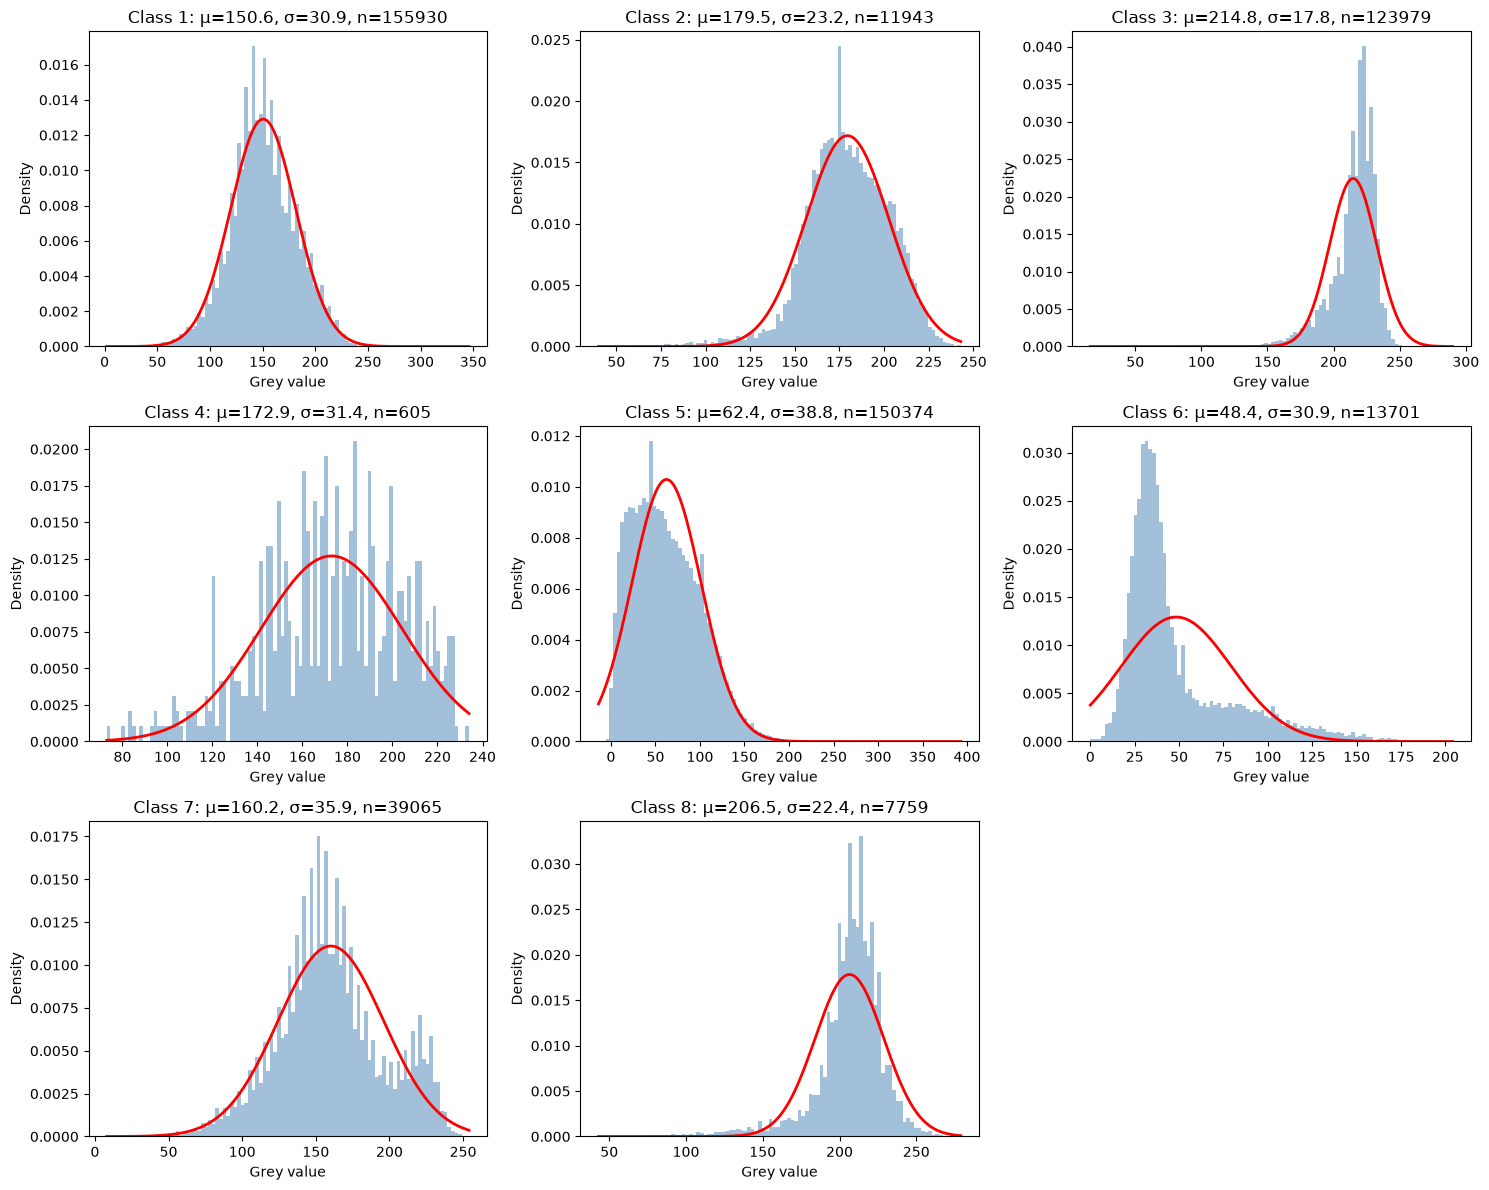

In [10]:
if __name__ == "__main__":
    main()